# First mini2p - maze recording tests

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [2]:
base_path = '/Volumes/behrens/meg/3x3_field_mag_training/rawdata/sub-01_id-M14/ses-02_date-20260506'
behavioral_path = f'{base_path}/behav'
imagining_path = f'{base_path}/funcimg'

In [3]:
#search for video files in the behavioral_path 
video_file = None
for file in os.listdir(behavioral_path):
    if file.endswith(".mp4") or file.endswith(".avi"):
        video_file = os.path.join(behavioral_path, file)
        print(f"Found video file: {video_file}")


Found video file: /Volumes/behrens/meg/3x3_field_mag_training/rawdata/sub-01_id-M14/ses-02_date-20260506/behav/._M14_2026-05-06-174346.mp4
Found video file: /Volumes/behrens/meg/3x3_field_mag_training/rawdata/sub-01_id-M14/ses-02_date-20260506/behav/M14_2026-05-06-174346.mp4


In [4]:
#load the video file using OpenCV
cap = cv2.VideoCapture(video_file)

In [5]:
#convert the video frames to numpy array
frames = []
while True:
    ret, frame = cap.read()
    if not ret:
        break
    frames.append(frame)

In [7]:
len(frames)

16618

In [8]:
#calculate the mean frame
mean_frame = np.mean(frames, axis=0).astype(np.uint8)


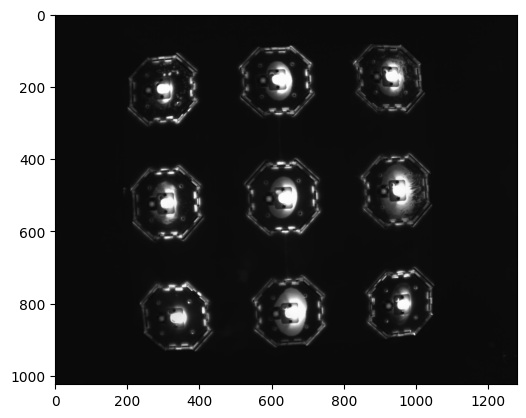

In [9]:
plt.imshow(mean_frame)

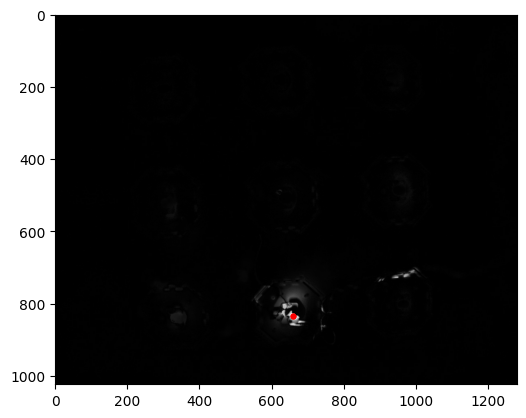

In [16]:
#display the first frame minus the mean frame
first_frame = frames[8000]
diff_frame = cv2.absdiff(first_frame, mean_frame)
max_diff = np.where(diff_frame == np.max(diff_frame))
plt.imshow(diff_frame)
plt.scatter(max_diff[1], max_diff[0], color='red', s=10)

In [25]:
position_list = []
for frame in frames:
    diff_frame = cv2.absdiff(frame, mean_frame)
    max_diff = np.where(diff_frame == np.max(diff_frame))
    position_list.append((max_diff[1][0], max_diff[0][0]))
position_array = np.array(position_list)

    

In [67]:
#detect big jumps in the position and mark them as outliers
position_corrected = position_array.copy().astype(float)
diff_position_x = np.diff(position_array[:,0], axis=0)
diff_position_y = np.diff(position_array[:,1], axis=0)
outliers = np.where(np.sqrt(diff_position_x**2 + diff_position_y**2) > 50)[0]
position_corrected[outliers] = np.nan

In [68]:
#for the nans in position_corrected, use a median filter around it to fill in the values
for i in range(len(position_corrected)):
    if np.isnan(position_corrected[i,0]):
        position_corrected[i,0] = np.nanmedian(position_corrected[max(0,i-10):min(len(position_corrected),i+10),0])
    if np.isnan(position_corrected[i,1]):
        position_corrected[i,1] = np.nanmedian(position_corrected[max(0,i-10):min(len(position_corrected),i+10),1])


In [73]:
len(outliers)

32

In [72]:
#repeat the outlier detection and correction process until there are no more outliers
while True:
    diff_position_x = np.diff(position_corrected[:,0], axis=0)
    diff_position_y = np.diff(position_corrected[:,1], axis=0)
    outliers = np.where(np.sqrt(diff_position_x**2 + diff_position_y**2) > 50)[0]
    if len(outliers) == 0:
        break
    position_corrected[outliers] = np.nan
    for i in range(len(position_corrected)):
        if np.isnan(position_corrected[i,0]):
            position_corrected[i,0] = np.nanmedian(position_corrected[max(0,i-10):min(len(position_corrected),i+10),0])
        if np.isnan(position_corrected[i,1]):
            position_corrected[i,1] = np.nanmedian(position_corrected[max(0,i-10):min(len(position_corrected),i+10),1])

KeyboardInterrupt: 

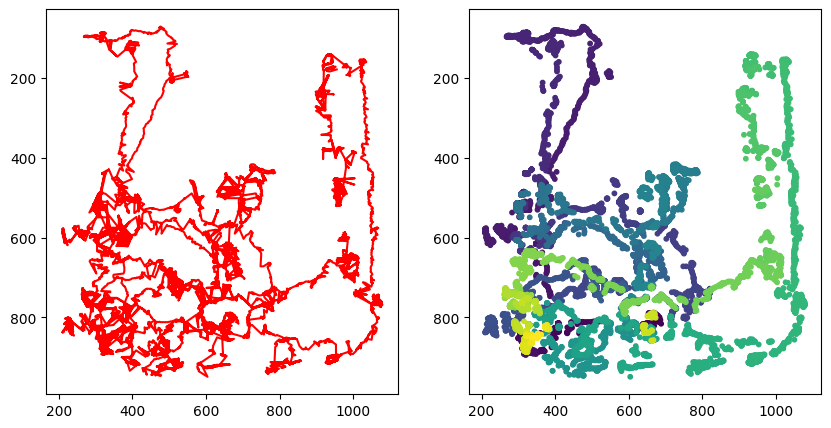

In [77]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.plot(position_corrected[:,0], position_corrected[:,1], color='red')
plt.gca().invert_yaxis()
plt.subplot(1,2,2)
plt.scatter(position_corrected[:,0], position_corrected[:,1], c=np.arange(len(position_corrected)), cmap='viridis', s=10)
plt.gca().invert_yaxis()

In [79]:
#save a copy of the video with the position of the mouse marked in each frame
output_video_file = os.path.join(behavioral_path, "output_video.mp4")
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(output_video_file, fourcc, 30.0, (frames[0].shape[1], frames[0].shape[0]))
for i in range(len(frames)):
    frame = frames[i].copy()
    if not np.isnan(position_corrected[i,0]) and not np.isnan(position_corrected[i,1]):
        cv2.circle(frame, (int(position_corrected[i,0]), int(position_corrected[i,1])), 5, (0,0,255), -1)
    out.write(frame)
out.release()